# Notebook 2 – Preprocessing, Training and Evaluation

**Goal:** train a semantic segmentation model that predicts 7 land-cover classes from Sentinel-1 data, and evaluate it on regions that were never seen during training.

**Input:** the 40 GeoTIFFs from Notebook 1 (Google Drive → `LULC_S1`).

**Output:** model weights, configuration file, figures and result tables in Google Drive → `LULC_S1_outputs`.

## Step 1 – Setup

**What:** install the libraries, connect Google Drive, fix the random seed and check the GPU.

**Why:** the fixed seed (42) makes the results reproducible; the GPU (NVIDIA T4) makes training much faster.

In [ ]:
!pip -q install rasterio segmentation-models-pytorch

import os, glob, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from google.colab import drive

drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/LULC_S1'           # created by Notebook 1
OUT_DIR  = '/content/drive/MyDrive/LULC_S1_outputs'   # weights, figures, tables
os.makedirs(OUT_DIR, exist_ok=True)

# Same random numbers every run -> results are reproducible
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)      # cuda = GPU is used

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


## Step 2 – Load the data

**What:** load the 40 GeoTIFFs and mark invalid pixels with the label 255.

**Invalid pixels:** no SAR observation (value −50), pixels outside the exported area (VV and VH = 0), or missing values. These pixels are ignored in training and evaluation.

In [ ]:
CLASS_NAMES = ['Tree', 'Grass/Shrub', 'Cropland', 'Built-up', 'Bare/Sparse', 'Water', 'Wetland']
N_CLASSES = len(CLASS_NAMES)
IGNORE = 255
# Colours similar to the official WorldCover legend (used in all maps)
CLASS_COLORS = ['#006400', '#ffbb22', '#f096ff', '#fa0000', '#b4b4b4', '#0064c8', '#0096a0']
CMAP = ListedColormap(CLASS_COLORS)

records = []
for f in sorted(glob.glob(f'{DATA_DIR}/*.tif')):
    split, region, month = os.path.basename(f)[:-4].split('_')
    with rasterio.open(f) as src:
        arr = src.read().astype(np.float32)          # shape (4, H, W)
    x, y = arr[:3], arr[3]
    invalid = (x[0] <= -49) | ((x[0] == 0) & (x[1] == 0)) | np.isnan(x).any(0) | np.isnan(y)
    y = np.where(invalid, IGNORE, y).astype(np.uint8)
    records.append(dict(split=split, region=region, month=month, x=x, y=y, invalid=invalid))

summary = pd.DataFrame([dict(split=r['split'], region=r['region'], month=r['month'],
                             size=f"{r['y'].shape[0]}x{r['y'].shape[1]}",
                             invalid_pct=round(100 * r['invalid'].mean(), 1)) for r in records])
print(len(records), 'files loaded')
summary

40 files loaded


,split,region,month,size,invalid_pct
0,test,hamburg,2021-01,1603x1600,0.2
1,test,hamburg,2021-04,1603x1600,0.2
2,test,hamburg,2021-07,1603x1600,0.2
3,test,hamburg,2021-10,1603x1600,0.2
4,test,lyon,2021-01,1707x1700,12.0
5,test,lyon,2021-04,1707x1700,12.0
6,test,lyon,2021-07,1707x1700,12.0
7,test,lyon,2021-10,1707x1700,12.0
8,train,blackforest,2021-01,1640x1634,4.6
9,train,blackforest,2021-04,1640x1634,4.6


## Step 3 – Normalisation

**What:** scale each band to mean 0 and standard deviation 1.

**Why:** neural networks train better with normalised inputs. The mean and standard deviation are calculated **only from the training regions**, so no information from the validation or test regions is used. The same values are saved and reused by the prototype.

In [ ]:
train_pixels = np.concatenate([r['x'][:, ~r['invalid']][:, ::10]          # every 10th pixel is enough
                               for r in records if r['split'] == 'train'], axis=1)
MEAN = train_pixels.mean(axis=1)
STD  = train_pixels.std(axis=1)
del train_pixels
print('Band means (dB):', MEAN.round(2), ' Band std:', STD.round(2))

for r in records:
    r['x'] = ((r['x'] - MEAN[:, None, None]) / STD[:, None, None]).astype(np.float32)
    r['x'][:, r['invalid']] = 0.0

Band means (dB): [ -9.55 -16.78   7.16]  Band std: [4.75 5.09 2.18]


## Step 4 – Check one example

**What:** show VV, VH and the WorldCover label for Paris (July 2021).

**Why:** a visual check that the radar image and the labels are correctly aligned (for example, the river Seine appears at the same place in both).

**Output:** `LULC_S1_outputs/fig_example_paris.png`

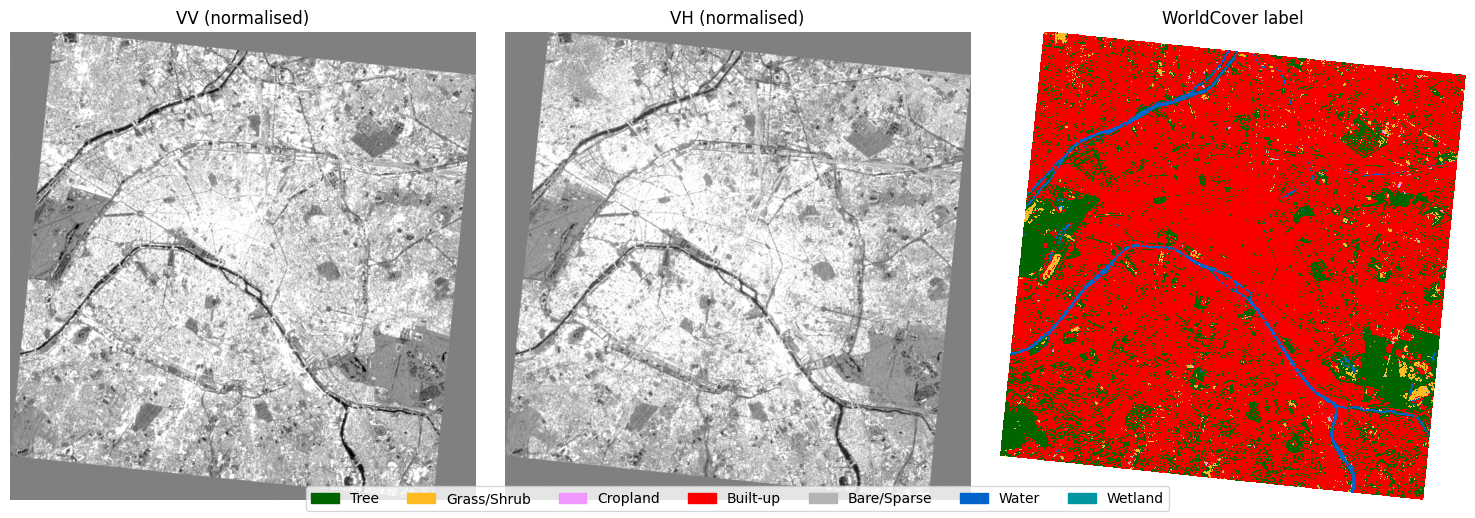

In [ ]:
r = next(r for r in records if r['region'] == 'paris' and r['month'] == '2021-07')
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(r['x'][0], cmap='gray', vmin=-2, vmax=2); ax[0].set_title('VV (normalised)')
ax[1].imshow(r['x'][1], cmap='gray', vmin=-2, vmax=2); ax[1].set_title('VH (normalised)')
lab = np.ma.masked_equal(r['y'], IGNORE)
ax[2].imshow(lab, cmap=CMAP, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation='nearest')
ax[2].set_title('WorldCover label')
for a in ax: a.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS]
fig.legend(handles, CLASS_NAMES, loc='lower center', ncol=N_CLASSES)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_example_paris.png', dpi=150, bbox_inches='tight'); plt.show()

## Step 5 – Class distribution and class weights

**What:** count the pixels of each class in the train, validation and test splits.

**Why:** the classes are imbalanced (much built-up and tree, very little bare land and wetland). Rare classes get a higher weight in the loss: weight = 1/√(frequency), scaled to a mean of 1.

**Output:** `LULC_S1_outputs/class_distribution.csv`, `LULC_S1_outputs/fig_class_distribution.png`

,train (%),val (%),test (%)
Tree,28.04,42.32,37.59
Grass/Shrub,13.83,7.20,9.71
Cropland,17.44,6.80,1.72
Built-up,28.58,42.29,44.38
Bare/Sparse,0.36,0.26,0.21
Water,7.56,1.10,6.30
Wetland,4.19,0.03,0.09


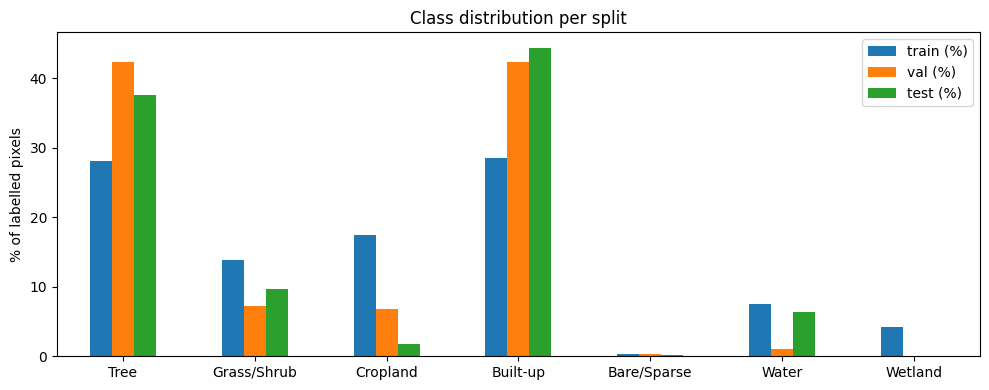

Class weights: {'Tree': np.float64(0.39), 'Grass/Shrub': np.float64(0.55), 'Cropland': np.float64(0.49), 'Built-up': np.float64(0.38), 'Bare/Sparse': np.float64(3.44), 'Water': np.float64(0.75), 'Wetland': np.float64(1.0)}


In [ ]:
counts = {s: np.zeros(N_CLASSES, dtype=np.int64) for s in ['train', 'val', 'test']}
for r in records:
    v = r['y'][r['y'] != IGNORE]
    counts[r['split']] += np.bincount(v, minlength=N_CLASSES)[:N_CLASSES]

dist = pd.DataFrame({s: 100 * c / c.sum() for s, c in counts.items()}, index=CLASS_NAMES).round(2)
dist.columns = [f'{s} (%)' for s in dist.columns]
dist.to_csv(f'{OUT_DIR}/class_distribution.csv')
display(dist)

dist.plot.bar(figsize=(10, 4), rot=0); plt.ylabel('% of labelled pixels'); plt.title('Class distribution per split')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_class_distribution.png', dpi=150); plt.show()

# Class weights: 1/sqrt(frequency), scaled to mean 1. sqrt = softer than pure inverse frequency,
# so very rare classes do not dominate the loss.
freq = counts['train'] / counts['train'].sum()
CLASS_WEIGHTS = 1.0 / np.sqrt(np.clip(freq, 1e-4, None))
CLASS_WEIGHTS = CLASS_WEIGHTS / CLASS_WEIGHTS.mean()
print('Class weights:', dict(zip(CLASS_NAMES, CLASS_WEIGHTS.round(2))))

## Step 6 – Patching and augmentation

**What:** cut the images into patches of 256 × 256 pixels (2.56 km × 2.56 km).
- Training: 50 % overlap (stride 128) for more samples. Validation and test: no overlap (stride 256), so each pixel is counted once.
- Patches with less than 50 % valid labels are removed.
- Augmentation during training: random 90° rotations and horizontal/vertical flips.

**Why:** full images do not fit into GPU memory. Land cover has no fixed orientation, so rotations and flips create realistic new examples.

In [ ]:
PATCH = 256

def make_index(split, stride, min_valid=0.5):
    idx = []
    for i, r in enumerate(records):
        if r['split'] != split:
            continue
        H, W = r['y'].shape
        for top in range(0, H - PATCH + 1, stride):
            for left in range(0, W - PATCH + 1, stride):
                if (r['y'][top:top + PATCH, left:left + PATCH] != IGNORE).mean() >= min_valid:
                    idx.append((i, top, left))
    return idx

class S1Patches(Dataset):
    def __init__(self, index, augment=False):
        self.index, self.augment = index, augment
    def __len__(self):
        return len(self.index)
    def __getitem__(self, k):
        i, t, l = self.index[k]
        x = records[i]['x'][:, t:t + PATCH, l:l + PATCH]
        y = records[i]['y'][t:t + PATCH, l:l + PATCH]
        if self.augment:
            rot = np.random.randint(4)
            x, y = np.rot90(x, rot, axes=(1, 2)), np.rot90(y, rot)
            if np.random.rand() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < 0.5: x, y = x[:, ::-1, :], y[::-1, :]
        return torch.from_numpy(x.copy()), torch.from_numpy(y.astype(np.int64).copy())

train_idx, val_idx, test_idx = make_index('train', 128), make_index('val', 256), make_index('test', 256)
print(f'Patches -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}')

BATCH = 16
train_dl = DataLoader(S1Patches(train_idx, augment=True), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
val_dl   = DataLoader(S1Patches(val_idx),  batch_size=BATCH, num_workers=2)
test_dl  = DataLoader(S1Patches(test_idx), batch_size=BATCH, num_workers=2)

Patches -> train: 3928, val: 144, test: 288


## Step 7 – Model variants

**What:** two U-Net models are compared.
- **Variant A – U-Net from scratch:** encoder with 32–64–128–256 filters, bottleneck 512, all weights start randomly (7.8 M parameters).
- **Variant B – U-Net with ResNet-34 encoder:** encoder pretrained on ImageNet (24.4 M parameters).

**Why U-Net:** it is the standard architecture for semantic segmentation of satellite images. The encoder learns *what* is in the image, the decoder decides *where* each class is, and skip connections keep fine details such as field borders and roads.

In [ ]:
class DoubleConv(nn.Sequential):
    def __init__(self, c_in, c_out):
        super().__init__(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                         nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class UNet(nn.Module):
    """Plain U-Net. Encoder: 32-64-128-256 filters, bottleneck 512, symmetric decoder with skip connections."""
    def __init__(self, in_ch=3, n_classes=7, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8]
        self.downs = nn.ModuleList()
        c = in_ch
        for c_out in ch:
            self.downs.append(DoubleConv(c, c_out)); c = c_out
        self.bottleneck = DoubleConv(ch[-1], ch[-1] * 2)
        self.ups, self.up_convs = nn.ModuleList(), nn.ModuleList()
        c = ch[-1] * 2
        for c_out in reversed(ch):
            self.ups.append(nn.ConvTranspose2d(c, c_out, 2, stride=2))
            self.up_convs.append(DoubleConv(c_out * 2, c_out)); c = c_out
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = conv(torch.cat([up(x), skip], dim=1))
        return self.head(x)

def build_model(variant):
    if variant == 'unet_scratch':
        return UNet(3, N_CLASSES)
    if variant == 'unet_resnet34':
        return smp.Unet('resnet34', encoder_weights='imagenet', in_channels=3, classes=N_CLASSES)
    raise ValueError(variant)

for v in ['unet_scratch', 'unet_resnet34']:
    n = sum(p.numel() for p in build_model(v).parameters())
    print(f'{v}: {n / 1e6:.1f} M parameters')

unet_scratch: 7.8 M parameters


unet_resnet34: 24.4 M parameters


## Step 8 – Evaluation metrics

**What:** all metrics are calculated from the confusion matrix; pixels with label 255 are ignored.
- **Overall accuracy (OA):** share of correctly classified pixels.
- **IoU per class:** TP / (TP + FP + FN).
- **mIoU:** mean IoU over all classes (main metric, every class counts equally).
- **F1 per class:** 2·TP / (2·TP + FP + FN).

In [ ]:
def update_confusion(cm, logits, target):
    pred = logits.argmax(1)
    m = target != IGNORE
    cm += torch.bincount(target[m] * N_CLASSES + pred[m], minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
    return cm

def compute_metrics(cm):
    cm = cm.double()
    tp = cm.diag(); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    iou = tp / (tp + fp + fn)                 # NaN if the class never appears and is never predicted
    f1 = 2 * tp / (2 * tp + fp + fn)
    present = cm.sum(1) > 0
    return dict(OA=(tp.sum() / cm.sum()).item(), mIoU=iou[present].mean().item(),
                IoU=iou.cpu().numpy(), F1=f1.cpu().numpy(), present=present.cpu().numpy())

## Step 9 – Training setup

**What:**
- Loss: weighted cross-entropy (weights from Step 5), label 255 ignored.
- Optimiser: AdamW with cosine learning-rate schedule, 25 epochs, batch size 16.
- Learning rate: 1e-3 for Variant A, 3e-4 for Variant B (lower, to protect the pretrained weights).
- Mixed precision for faster training.

**Model selection:** after every epoch the model is evaluated on the validation region (Munich); the weights with the highest validation mIoU are saved. The test regions are used only once, at the end.

In [ ]:
EPOCHS = 25
criterion = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE),
                                ignore_index=IGNORE)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    cm = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
            logits = model(x)
        total_loss += criterion(logits.float(), y).item() * len(x); n += len(x)
        cm = update_confusion(cm, logits, y)
    return total_loss / n, compute_metrics(cm), cm

def train(variant, lr):
    torch.manual_seed(SEED)
    model = build_model(variant).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler(enabled=DEVICE == 'cuda')
    history, best_miou = [], -1
    for epoch in range(1, EPOCHS + 1):
        model.train(); t0 = time.time()
        cm = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE); run_loss, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
                logits = model(x)
                loss = criterion(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(x); n += len(x)
            cm = update_confusion(cm, logits.detach(), y)
        sched.step()
        tr = compute_metrics(cm)
        val_loss, va, _ = evaluate(model, val_dl)
        history.append(dict(epoch=epoch, train_loss=run_loss / n, val_loss=val_loss,
                            train_mIoU=tr['mIoU'], val_mIoU=va['mIoU'], train_OA=tr['OA'], val_OA=va['OA']))
        flag = ''
        if va['mIoU'] > best_miou:
            best_miou = va['mIoU']; flag = '  <- best, saved'
            torch.save(model.state_dict(), f'{OUT_DIR}/{variant}_best.pt')
        print(f"{variant} | epoch {epoch:2d} | train loss {run_loss / n:.3f} | val loss {val_loss:.3f} | "
              f"val OA {va['OA']:.3f} | val mIoU {va['mIoU']:.3f} | {time.time() - t0:.0f}s{flag}")
    hist = pd.DataFrame(history); hist.to_csv(f'{OUT_DIR}/{variant}_history.csv', index=False)
    return hist

## Step 10 – Train Variant A (U-Net from scratch)

**Output:** `LULC_S1_outputs/unet_scratch_best.pt`, `LULC_S1_outputs/unet_scratch_history.csv`

In [ ]:
hist_a = train('unet_scratch', lr=1e-3)

unet_scratch | epoch  1 | train loss 1.113 | val loss 0.882 | val OA 0.684 | val mIoU 0.312 | 46s  <- best, saved
unet_scratch | epoch  2 | train loss 0.959 | val loss 0.832 | val OA 0.697 | val mIoU 0.320 | 44s  <- best, saved
unet_scratch | epoch  3 | train loss 0.893 | val loss 0.789 | val OA 0.709 | val mIoU 0.348 | 45s  <- best, saved
unet_scratch | epoch  4 | train loss 0.846 | val loss 0.801 | val OA 0.698 | val mIoU 0.344 | 46s
unet_scratch | epoch  5 | train loss 0.832 | val loss 0.788 | val OA 0.713 | val mIoU 0.346 | 48s
unet_scratch | epoch  6 | train loss 0.814 | val loss 0.788 | val OA 0.697 | val mIoU 0.340 | 49s
unet_scratch | epoch  7 | train loss 0.770 | val loss 0.786 | val OA 0.706 | val mIoU 0.325 | 50s
unet_scratch | epoch  8 | train loss 0.747 | val loss 0.764 | val OA 0.701 | val mIoU 0.340 | 50s
unet_scratch | epoch  9 | train loss 0.732 | val loss 0.847 | val OA 0.670 | val mIoU 0.308 | 50s
unet_scratch | epoch 10 | train loss 0.719 | val loss 0.762 | val OA 0

## Step 11 – Train Variant B (U-Net + ResNet-34)

**Output:** `LULC_S1_outputs/unet_resnet34_best.pt`, `LULC_S1_outputs/unet_resnet34_history.csv`

In [13]:
hist_b = train('unet_resnet34', lr=3e-4)

unet_resnet34 | epoch  1 | train loss 1.002 | val loss 0.805 | val OA 0.699 | val mIoU 0.350 | 39s  <- best, saved
unet_resnet34 | epoch  2 | train loss 0.752 | val loss 0.802 | val OA 0.693 | val mIoU 0.340 | 38s
unet_resnet34 | epoch  3 | train loss 0.684 | val loss 0.792 | val OA 0.700 | val mIoU 0.342 | 38s
unet_resnet34 | epoch  4 | train loss 0.643 | val loss 0.812 | val OA 0.690 | val mIoU 0.339 | 38s
unet_resnet34 | epoch  5 | train loss 0.607 | val loss 0.747 | val OA 0.712 | val mIoU 0.352 | 39s  <- best, saved
unet_resnet34 | epoch  6 | train loss 0.608 | val loss 0.732 | val OA 0.714 | val mIoU 0.364 | 39s  <- best, saved
unet_resnet34 | epoch  7 | train loss 0.573 | val loss 0.811 | val OA 0.685 | val mIoU 0.348 | 39s
unet_resnet34 | epoch  8 | train loss 0.571 | val loss 0.730 | val OA 0.716 | val mIoU 0.374 | 39s  <- best, saved
unet_resnet34 | epoch  9 | train loss 0.534 | val loss 0.732 | val OA 0.716 | val mIoU 0.366 | 39s
unet_resnet34 | epoch 10 | train loss 0.522 |

## Step 12 – Training curves

**What:** loss and mIoU of both variants for training and validation.

**How to read:** if the training loss keeps falling but the validation loss rises, the model is overfitting. Here the validation loss decreases and then becomes flat.

**Output:** `LULC_S1_outputs/fig_training_curves.png`

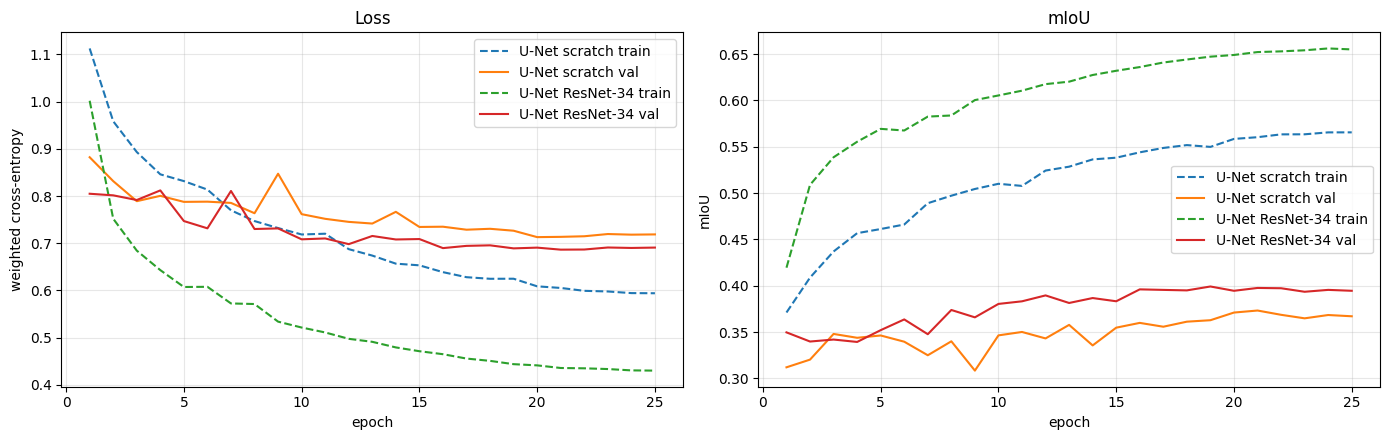

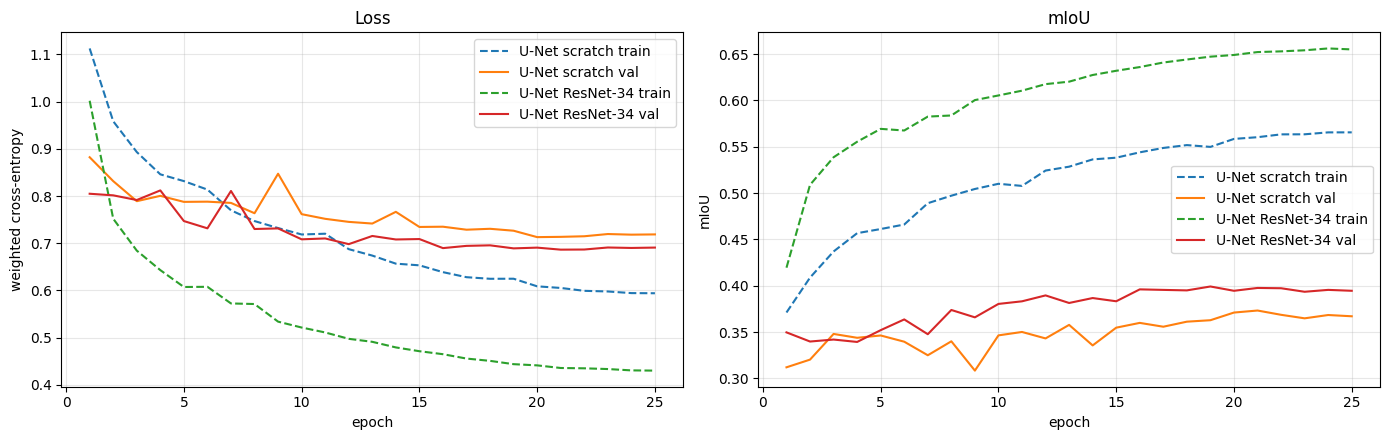

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for hist, name in [(hist_a, 'U-Net scratch'), (hist_b, 'U-Net ResNet-34')]:
    ax[0].plot(hist.epoch, hist.train_loss, '--', label=f'{name} train')
    ax[0].plot(hist.epoch, hist.val_loss, '-', label=f'{name} val')
    ax[1].plot(hist.epoch, hist.train_mIoU, '--', label=f'{name} train')
    ax[1].plot(hist.epoch, hist.val_mIoU, '-', label=f'{name} val')
ax[0].set(title='Loss', xlabel='epoch', ylabel='weighted cross-entropy')
ax[1].set(title='mIoU', xlabel='epoch', ylabel='mIoU')
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_training_curves.png', dpi=150); plt.show()

## Step 13 – Evaluation on the test regions (Lyon, Hamburg)

**What:** evaluate both variants with their best checkpoint on the unseen test regions and calculate OA, mIoU, IoU and F1 per class.

**Output:** `LULC_S1_outputs/test_model_comparison.csv`, `LULC_S1_outputs/test_per_class_unet_resnet34.csv`

In [15]:
results, cms = {}, {}
for variant in ['unet_scratch', 'unet_resnet34']:
    model = build_model(variant).to(DEVICE)
    model.load_state_dict(torch.load(f'{OUT_DIR}/{variant}_best.pt', map_location=DEVICE))
    _, m, cm = evaluate(model, test_dl)
    results[variant], cms[variant] = m, cm.cpu().numpy()

comparison = pd.DataFrame({v: {'OA': m['OA'], 'mIoU': m['mIoU']} for v, m in results.items()}).T.round(4)
comparison.to_csv(f'{OUT_DIR}/test_model_comparison.csv')
display(comparison)

BEST = comparison['mIoU'].idxmax()
print('Best variant on test:', BEST)
best = results[BEST]
per_class = pd.DataFrame({'IoU': best['IoU'], 'F1': best['F1'],
                          'test pixels': cms[BEST].sum(1)}, index=CLASS_NAMES).round(4)
per_class.to_csv(f'{OUT_DIR}/test_per_class_{BEST}.csv')
per_class

,OA,mIoU
unet_scratch,0.7416,0.3680
unet_resnet34,0.7370,0.3731


,OA,mIoU
unet_scratch,0.7416,0.3680
unet_resnet34,0.7370,0.3731


Best variant on test: unet_resnet34
Best variant on test: unet_resnet34


,IoU,F1,test pixels
Tree,0.5705,0.7265,7041540
Grass/Shrub,0.4509,0.6215,1663880
Cropland,0.2009,0.3345,240892
Built-up,0.6326,0.7750,8047096
Bare/Sparse,0.0312,0.0606,37352
Water,0.7205,0.8376,1189156
Wetland,0.0048,0.0095,13204


,IoU,F1,test pixels
Tree,0.5705,0.7265,7041540
Grass/Shrub,0.4509,0.6215,1663880
Cropland,0.2009,0.3345,240892
Built-up,0.6326,0.7750,8047096
Bare/Sparse,0.0312,0.0606,37352
Water,0.7205,0.8376,1189156
Wetland,0.0048,0.0095,13204


## Step 14 – Confusion matrix

**What:** confusion matrix of the final model, normalised per true class (each row sums to 1).

**Why:** the off-diagonal values show which classes are confused, for example cropland with grass/shrub.

**Output:** `LULC_S1_outputs/fig_confusion_matrix.png`

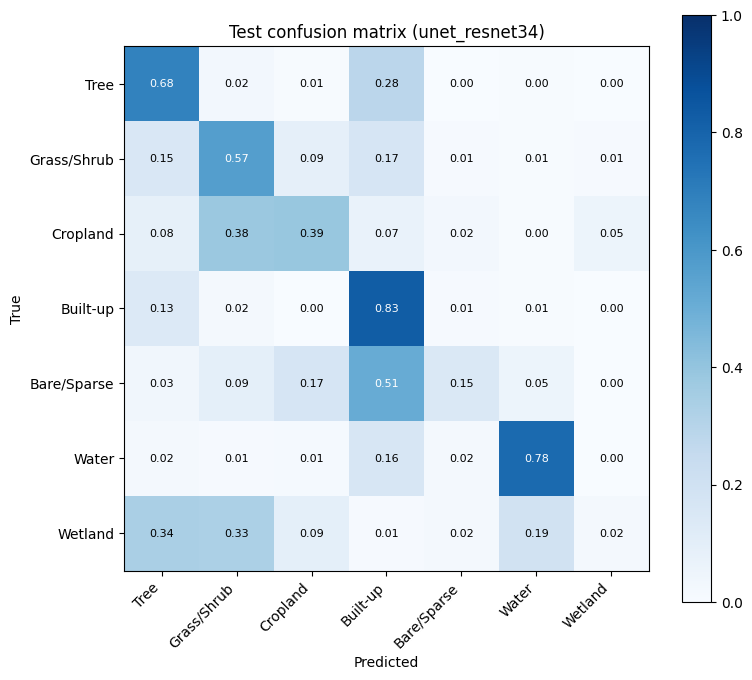

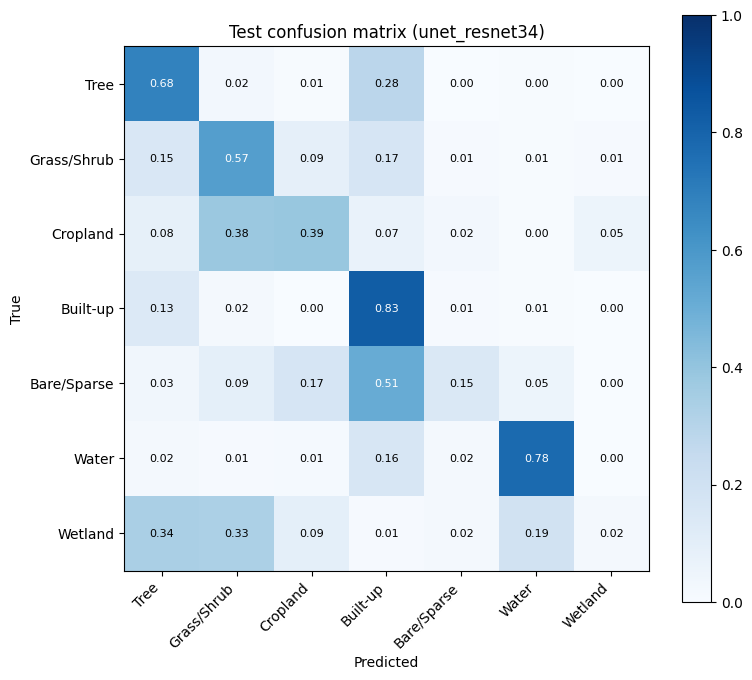

In [16]:
cm = cms[BEST].astype(float)
cm_norm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=45, ha='right'); ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center',
                color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=8)
ax.set(xlabel='Predicted', ylabel='True', title=f'Test confusion matrix ({BEST})')
plt.colorbar(im); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_confusion_matrix.png', dpi=150); plt.show()

## Step 15 – Results per season

**What:** test results separately for January, April, July and October.

**Why:** the land cover is the same in all four months, but the radar signal changes with the season. Differences between the seasons show how strong this effect is.

**Output:** `LULC_S1_outputs/test_per_season.csv`

In [17]:
model = build_model(BEST).to(DEVICE)
model.load_state_dict(torch.load(f'{OUT_DIR}/{BEST}_best.pt', map_location=DEVICE))
season = {'2021-01': 'Winter (Jan)', '2021-04': 'Spring (Apr)', '2021-07': 'Summer (Jul)', '2021-10': 'Autumn (Oct)'}
rows = []
for month, label in season.items():
    idx = [t for t in test_idx if records[t[0]]['month'] == month]
    _, m, _ = evaluate(model, DataLoader(S1Patches(idx), batch_size=BATCH))
    rows.append(dict(season=label, OA=round(m['OA'], 4), mIoU=round(m['mIoU'], 4)))
seasonal = pd.DataFrame(rows); seasonal.to_csv(f'{OUT_DIR}/test_per_season.csv', index=False)
seasonal

,season,OA,mIoU
0,Winter (Jan),0.7365,0.3772
1,Spring (Apr),0.7436,0.3768
2,Summer (Jul),0.7335,0.3633
3,Autumn (Oct),0.7343,0.3753


,season,OA,mIoU
0,Winter (Jan),0.7365,0.3772
1,Spring (Apr),0.7436,0.3768
2,Summer (Jul),0.7335,0.3633
3,Autumn (Oct),0.7343,0.3753


## Step 16 – Example predictions

**What:** VV input, WorldCover label and model prediction for four test patches.

**Output:** `LULC_S1_outputs/fig_test_predictions.png`

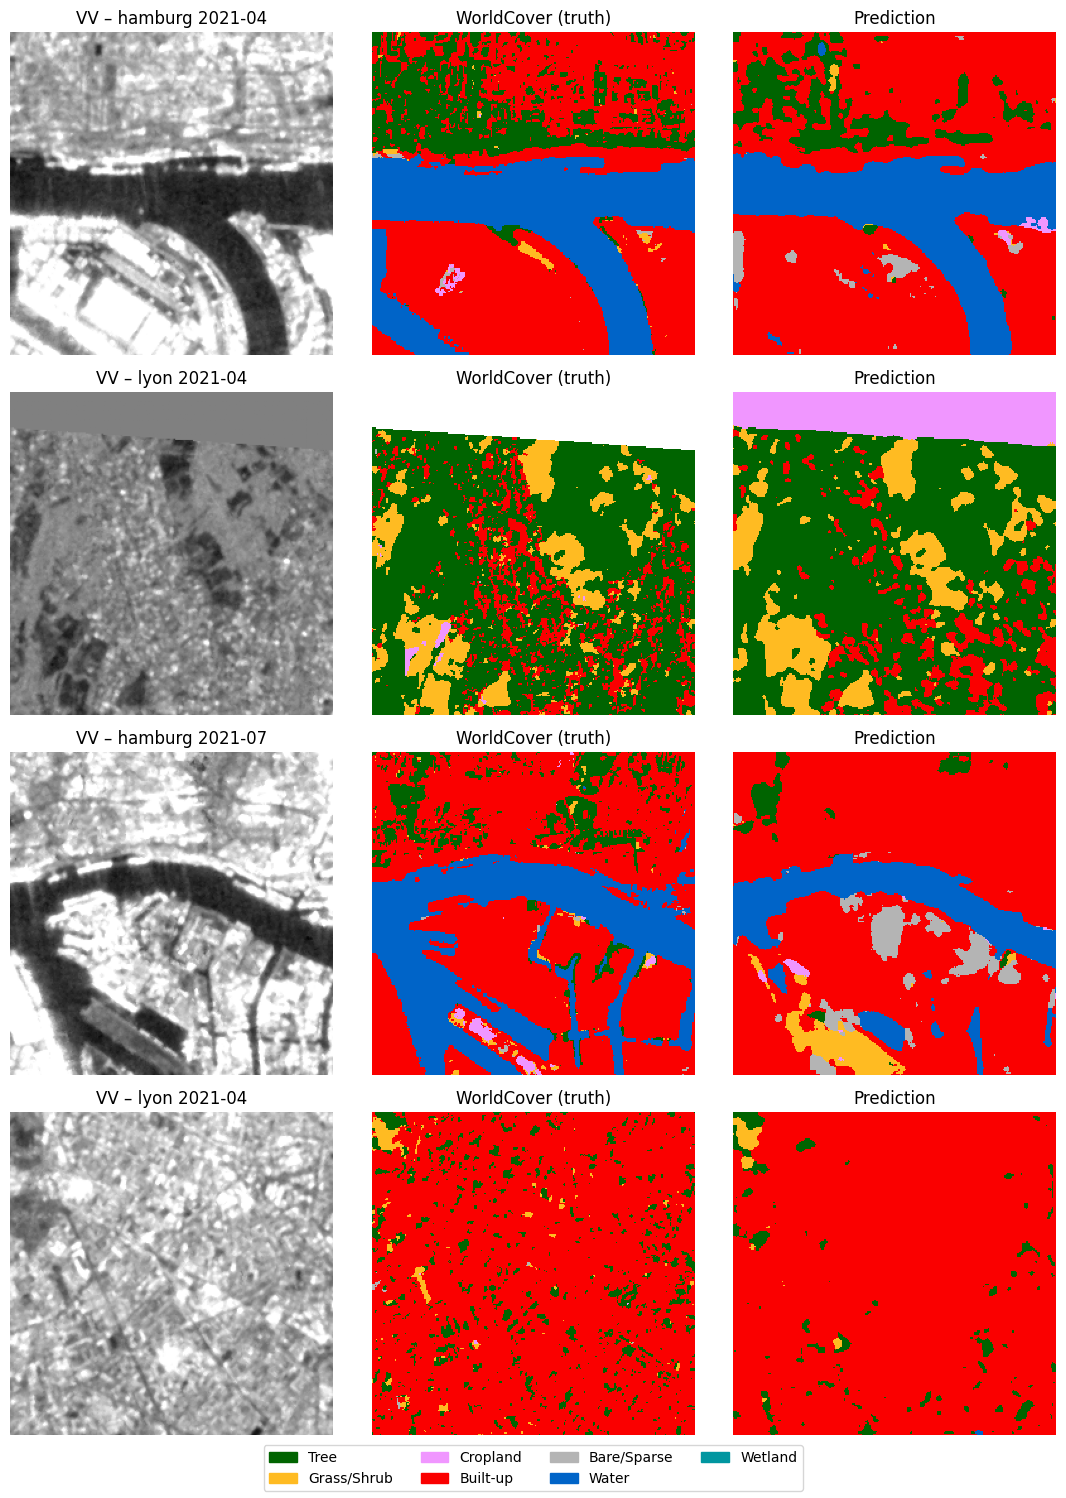

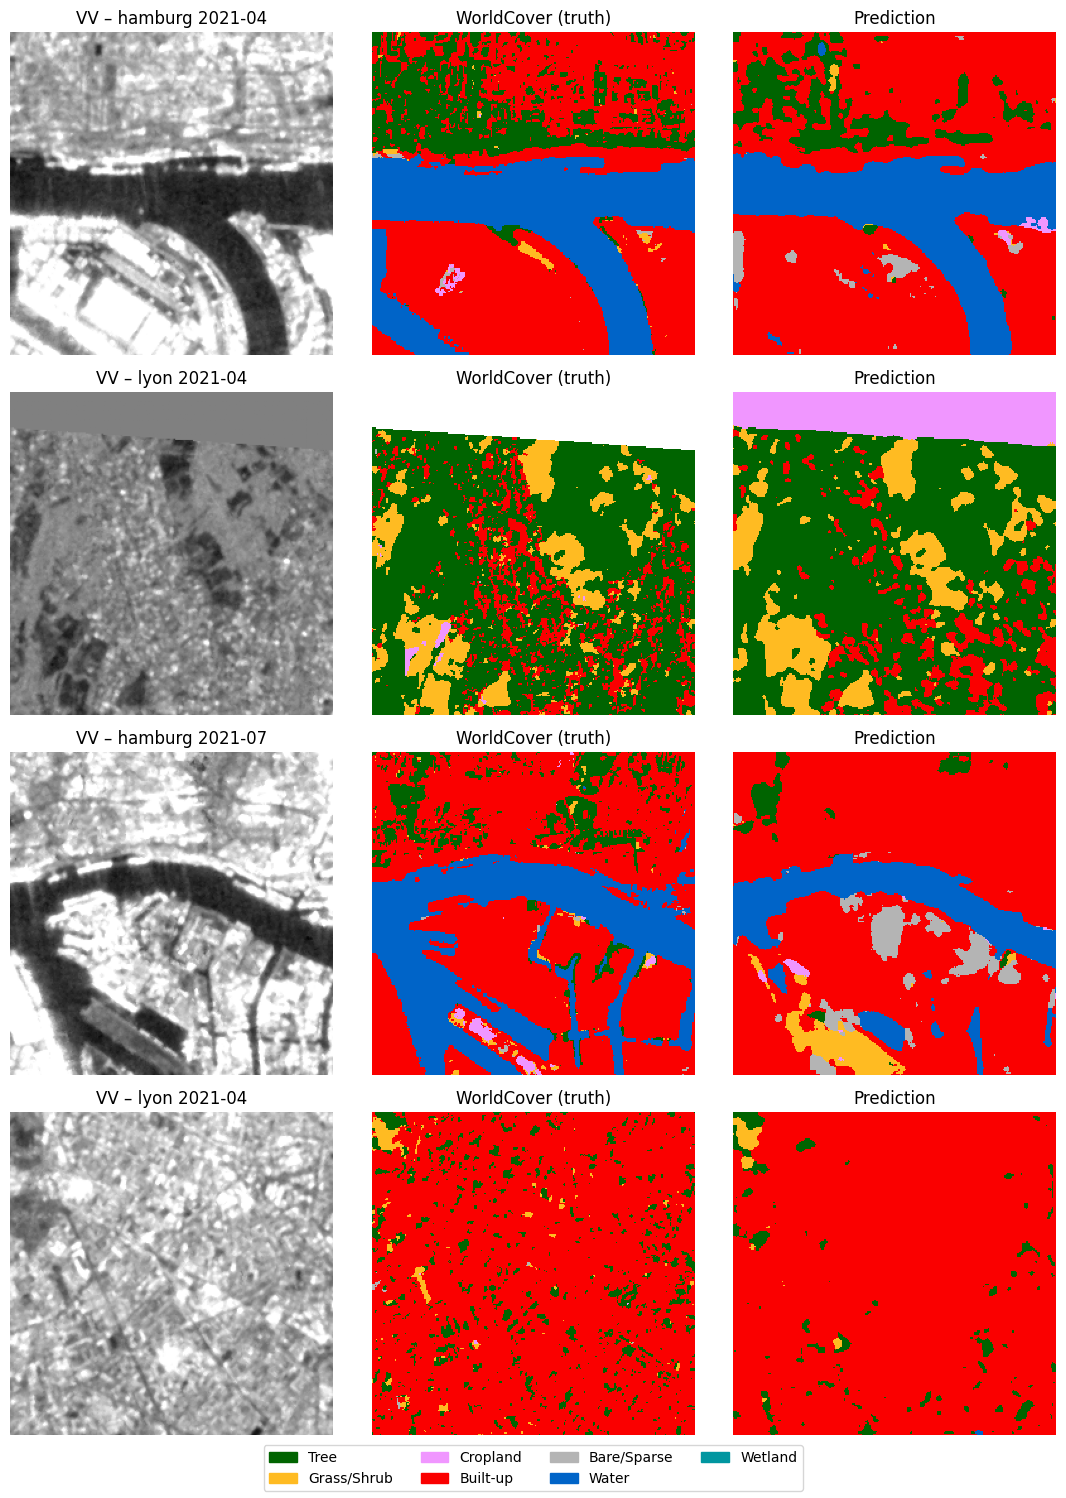

In [18]:
model.eval()
picks = np.random.RandomState(0).choice(len(test_idx), 4, replace=False)
fig, ax = plt.subplots(4, 3, figsize=(11, 15))
for row, k in enumerate(picks):
    x, y = S1Patches(test_idx)[k]
    with torch.no_grad():
        pred = model(x[None].to(DEVICE)).argmax(1)[0].cpu().numpy()
    i, t, l = test_idx[k]
    ax[row, 0].imshow(x[0], cmap='gray', vmin=-2, vmax=2)
    ax[row, 0].set_title(f"VV – {records[i]['region']} {records[i]['month']}")
    ax[row, 1].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=CMAP, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation='nearest')
    ax[row, 1].set_title('WorldCover (truth)')
    ax[row, 2].imshow(pred, cmap=CMAP, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation='nearest')
    ax[row, 2].set_title('Prediction')
for a in ax.ravel(): a.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS]
fig.legend(handles, CLASS_NAMES, loc='lower center', ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(f'{OUT_DIR}/fig_test_predictions.png', dpi=150); plt.show()

## Step 17 – Save the files for the prototype

**What:** save the final model and its configuration (model variant, class names and colours, normalisation values, grid settings).

**Why:** the prototype must process new data exactly like the training data.

**Output:** `LULC_S1_outputs/model_best.pt`, `LULC_S1_outputs/model_config.json`

In [19]:
config = dict(variant=BEST, class_names=CLASS_NAMES, class_colors=CLASS_COLORS,
              band_order=['VV', 'VH', 'VV_VH'], mean=MEAN.tolist(), std=STD.tolist(),
              patch_size=PATCH, scale_m=10, crs='EPSG:3035', training_year=2021)
json.dump(config, open(f'{OUT_DIR}/model_config.json', 'w'), indent=2)

import shutil
shutil.copy(f'{OUT_DIR}/{BEST}_best.pt', f'{OUT_DIR}/model_best.pt')
print('Saved:', sorted(os.listdir(OUT_DIR)))

Saved: ['class_distribution.csv', 'fig_class_distribution.png', 'fig_confusion_matrix.png', 'fig_example_paris.png', 'fig_test_predictions.png', 'fig_training_curves.png', 'model_best.pt', 'model_config.json', 'test_model_comparison.csv', 'test_per_class_unet_resnet34.csv', 'test_per_season.csv', 'unet_resnet34_best.pt', 'unet_resnet34_history.csv', 'unet_scratch_best.pt', 'unet_scratch_history.csv']
Saved: ['class_distribution.csv', 'fig_class_distribution.png', 'fig_confusion_matrix.png', 'fig_example_paris.png', 'fig_test_predictions.png', 'fig_training_curves.png', 'model_best.pt', 'model_config.json', 'test_model_comparison.csv', 'test_per_class_unet_resnet34.csv', 'test_per_season.csv', 'unet_resnet34_best.pt', 'unet_resnet34_history.csv', 'unet_scratch_best.pt', 'unet_scratch_history.csv']
